# Day 4 — Technical Indicators & Feature Engineering

## Goal

Today I am learning how to transform historical stock data
into features that could potentially be used by a machine-learning model.

Topics:
- Simple Moving Average (SMA)
- Exponential Moving Average (EMA)
- Momentum
- RSI
- MACD
- Bollinger Bands
- Volume features
- Feature vs target
- Avoiding future-information leakage

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
data = pd.read_csv(
    "../data/raw/AAPL_daily_raw.csv",
    index_col="Date",
    parse_dates=True
)

data = data.sort_index()

data.head()

,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits,daily_return
Date,,,,,,,,,
2015-01-02 00:00:00-05:00,27.847500,27.860001,26.837500,27.332500,24.171755,212818400,0.0,0.0,NaN
2015-01-05 00:00:00-05:00,27.072500,27.162500,26.352501,26.562500,23.490799,257142000,0.0,0.0,-0.028172
2015-01-06 00:00:00-05:00,26.635000,26.857500,26.157499,26.565001,23.493013,263188400,0.0,0.0,0.000094
2015-01-07 00:00:00-05:00,26.799999,27.049999,26.674999,26.937500,23.822430,160423600,0.0,0.0,0.014022
2015-01-08 00:00:00-05:00,27.307501,28.037500,27.174999,27.972500,24.737757,237458000,0.0,0.0,0.038423


In [4]:
data["daily_return"] = data["Adj Close"].pct_change()

In [5]:
data[["Adj Close", "daily_return"]].head()

,Adj Close,daily_return
Date,,
2015-01-02 00:00:00-05:00,24.171755,NaN
2015-01-05 00:00:00-05:00,23.490799,-0.028172
2015-01-06 00:00:00-05:00,23.493013,0.000094
2015-01-07 00:00:00-05:00,23.822430,0.014022
2015-01-08 00:00:00-05:00,24.737757,0.038423


In [19]:
data["SMA_20"] = (data["Adj Close"].rolling(20).mean())

In [8]:
data[["Adj Close", "SMA_20"]].tail(5)

,Adj Close,SMA_20
Date,,
2025-12-24 00:00:00-05:00,273.066711,276.399649
2025-12-26 00:00:00-05:00,272.657837,276.192712
2025-12-29 00:00:00-05:00,273.016876,275.938904
2025-12-30 00:00:00-05:00,272.338684,275.439264
2025-12-31 00:00:00-05:00,271.122009,274.724709


In [9]:
data["SMA_50"] = (
    data["Adj Close"]
    .rolling(50)
    .mean()
)

data["SMA_200"] = (
    data["Adj Close"]
    .rolling(200)
    .mean()
)

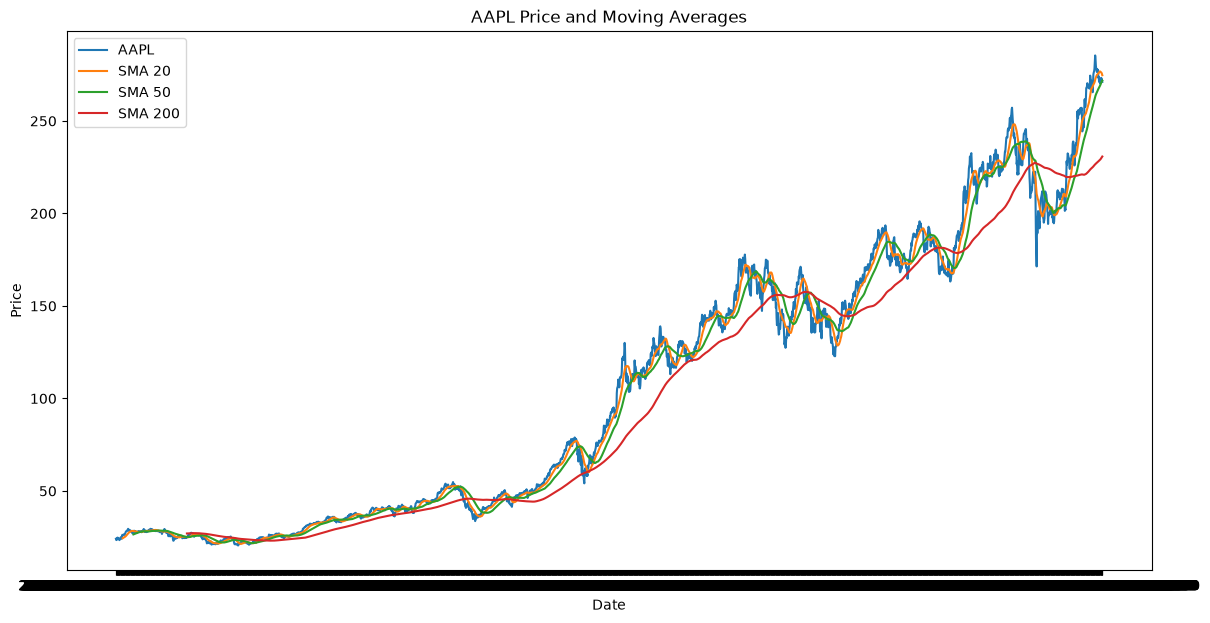

In [10]:
plt.figure(figsize=(14, 7))

plt.plot(
    data.index,
    data["Adj Close"],
    label="AAPL"
)

plt.plot(
    data.index,
    data["SMA_20"],
    label="SMA 20"
)

plt.plot(
    data.index,
    data["SMA_50"],
    label="SMA 50"
)

plt.plot(
    data.index,
    data["SMA_200"],
    label="SMA 200"
)

plt.title("AAPL Price and Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()

plt.show()

In [21]:
data[["Adj Close", "SMA_20", "price_to_SMA20"]].iloc[15:25]

,Adj Close,SMA_20,price_to_SMA20
Date,,,
2015-01-26 00:00:00-05:00,25.005264,NaN,NaN
2015-01-27 00:00:00-05:00,24.129749,NaN,NaN
2015-01-28 00:00:00-05:00,25.493877,NaN,NaN
2015-01-29 00:00:00-05:00,26.287584,NaN,NaN
2015-01-30 00:00:00-05:00,25.902895,24.461717,0.058916
2015-02-02 00:00:00-05:00,26.227896,24.564524,0.067714
2015-02-03 00:00:00-05:00,26.232323,24.701600,0.061969
2015-02-04 00:00:00-05:00,26.433504,24.848625,0.063781
2015-02-05 00:00:00-05:00,26.622175,24.988612,0.065372


In [26]:
data["price_to_SMA20"] = (
    data["Adj Close"] / data["SMA_20"] - 1
)

data[["Adj Close", "SMA_20", "price_to_SMA20"]].dropna().head(10)

,Adj Close,SMA_20,price_to_SMA20
Date,,,
2015-01-30 00:00:00-05:00,25.902895,24.461717,0.058916
2015-02-02 00:00:00-05:00,26.227896,24.564524,0.067714
2015-02-03 00:00:00-05:00,26.232323,24.701600,0.061969
2015-02-04 00:00:00-05:00,26.433504,24.848625,0.063781
2015-02-05 00:00:00-05:00,26.622175,24.988612,0.065372
2015-02-06 00:00:00-05:00,26.397993,25.071624,0.052903
2015-02-09 00:00:00-05:00,26.573347,25.162077,0.056087
2015-02-10 00:00:00-05:00,27.083855,25.308566,0.070146
2015-02-11 00:00:00-05:00,27.718664,25.476073,0.088027


In [27]:
data["SMA20_to_SMA50"] = (
    data["SMA_20"] / data["SMA_50"] - 1
)

In [28]:
data["EMA_12"] = (
    data["Adj Close"]
    .ewm(span=12, adjust=False)
    .mean()
)

data["EMA_26"] = (
    data["Adj Close"]
    .ewm(span=26, adjust=False)
    .mean()
)

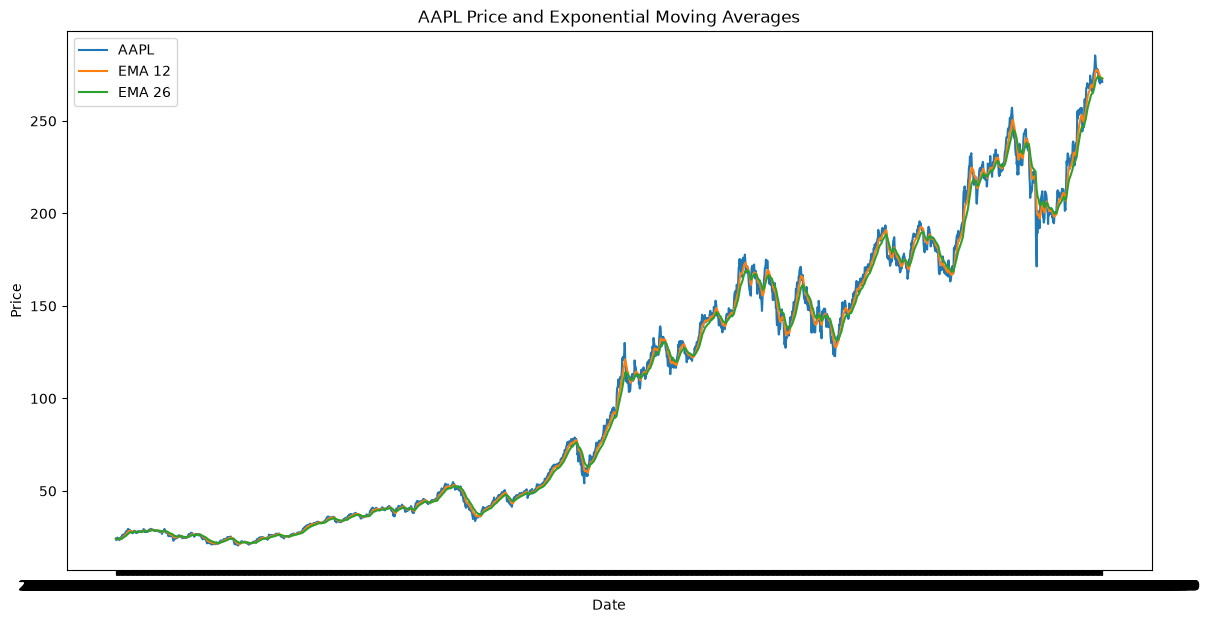

In [29]:
plt.figure(figsize=(14, 7))

plt.plot(
    data.index,
    data["Adj Close"],
    label="AAPL"
)

plt.plot(
    data.index,
    data["EMA_12"],
    label="EMA 12"
)

plt.plot(
    data.index,
    data["EMA_26"],
    label="EMA 26"
)

plt.title("AAPL Price and Exponential Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()

plt.show()

In [38]:
data["momentum_10d"] = (
    data["Adj Close"] / data["Adj Close"].shift(10) - 1
)

data[["Adj Close", "momentum_10d"]].dropna().head(5)

,Adj Close,momentum_10d
Date,,
2015-01-16 00:00:00-05:00,23.433321,-0.030549
2015-01-20 00:00:00-05:00,24.036882,0.023247
2015-01-21 00:00:00-05:00,24.220398,0.030962
2015-01-22 00:00:00-05:00,24.850502,0.043156
2015-01-23 00:00:00-05:00,24.978737,0.009741


In [39]:
data[["Adj Close"]].head(10)

,Adj Close
Date,
2015-01-02 00:00:00-05:00,24.171755
2015-01-05 00:00:00-05:00,23.490799
2015-01-06 00:00:00-05:00,23.493013
2015-01-07 00:00:00-05:00,23.822430
2015-01-08 00:00:00-05:00,24.737757
2015-01-09 00:00:00-05:00,24.764284
2015-01-12 00:00:00-05:00,24.154066
2015-01-13 00:00:00-05:00,24.368534
2015-01-14 00:00:00-05:00,24.275665


In [46]:
data["previous_close"] = (data["Adj Close"].shift(1))
data[["Adj Close", "previous_close"]].head(10)

,Adj Close,previous_close
Date,,
2015-01-02 00:00:00-05:00,24.171755,NaN
2015-01-05 00:00:00-05:00,23.490799,24.171755
2015-01-06 00:00:00-05:00,23.493013,23.490799
2015-01-07 00:00:00-05:00,23.822430,23.493013
2015-01-08 00:00:00-05:00,24.737757,23.822430
2015-01-09 00:00:00-05:00,24.764284,24.737757
2015-01-12 00:00:00-05:00,24.154066,24.764284
2015-01-13 00:00:00-05:00,24.368534,24.154066
2015-01-14 00:00:00-05:00,24.275665,24.368534


In [47]:
delta = data["Adj Close"].diff()

In [48]:
gain = delta.clip(lower=0)

loss = -delta.clip(upper=0)

In [49]:
avg_gain = gain.ewm(
    alpha=1/14,
    adjust=False
).mean()

avg_loss = loss.ewm(
    alpha=1/14,
    adjust=False
).mean()

In [50]:
rs = avg_gain / avg_loss

In [54]:
data["RSI_14"] = 100 - (100 / (1 + rs))

data[["Adj Close", "RSI_14"]].tail(10)

,Adj Close,RSI_14
Date,,
2025-12-17 00:00:00-05:00,271.102081,45.186622
2025-12-18 00:00:00-05:00,271.451111,45.918246
2025-12-19 00:00:00-05:00,272.927155,49.017416
2025-12-22 00:00:00-05:00,270.234436,44.057330
2025-12-23 00:00:00-05:00,271.620667,47.029036
2025-12-24 00:00:00-05:00,273.066711,50.012074
2025-12-26 00:00:00-05:00,272.657837,49.168925
2025-12-29 00:00:00-05:00,273.016876,49.966601
2025-12-30 00:00:00-05:00,272.338684,48.420900


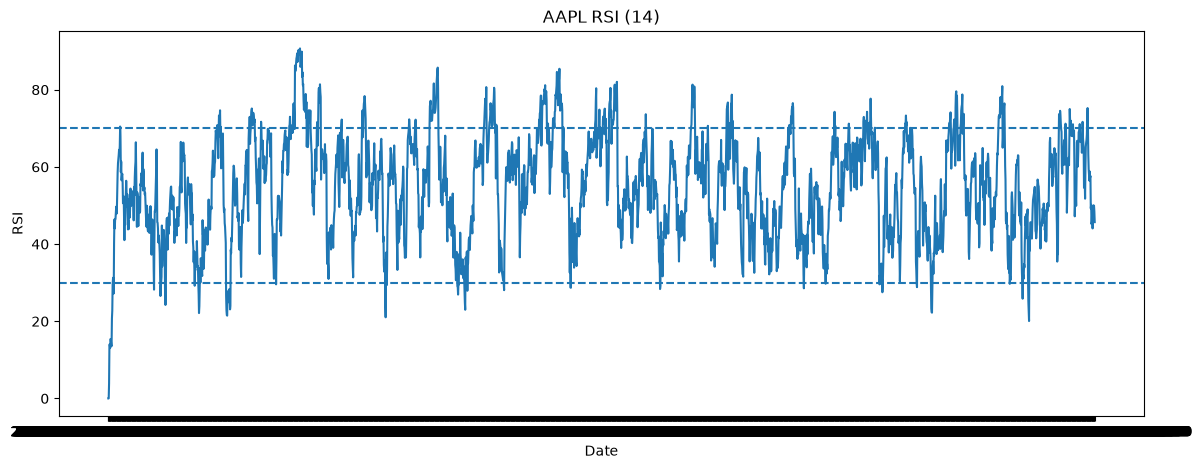

In [55]:
plt.figure(figsize=(14, 5))

plt.plot(
    data.index,
    data["RSI_14"]
)

plt.axhline(70, linestyle="--")
plt.axhline(30, linestyle="--")

plt.title("AAPL RSI (14)")
plt.xlabel("Date")
plt.ylabel("RSI")

plt.show()

In [56]:
data["MACD"] = (
    data["EMA_12"] - data["EMA_26"]
)

In [57]:
data["MACD_signal"] = (
    data["MACD"]
    .ewm(span=9, adjust=False)
    .mean()
)

In [58]:
data["MACD_hist"] = (
    data["MACD"] - data["MACD_signal"]
)

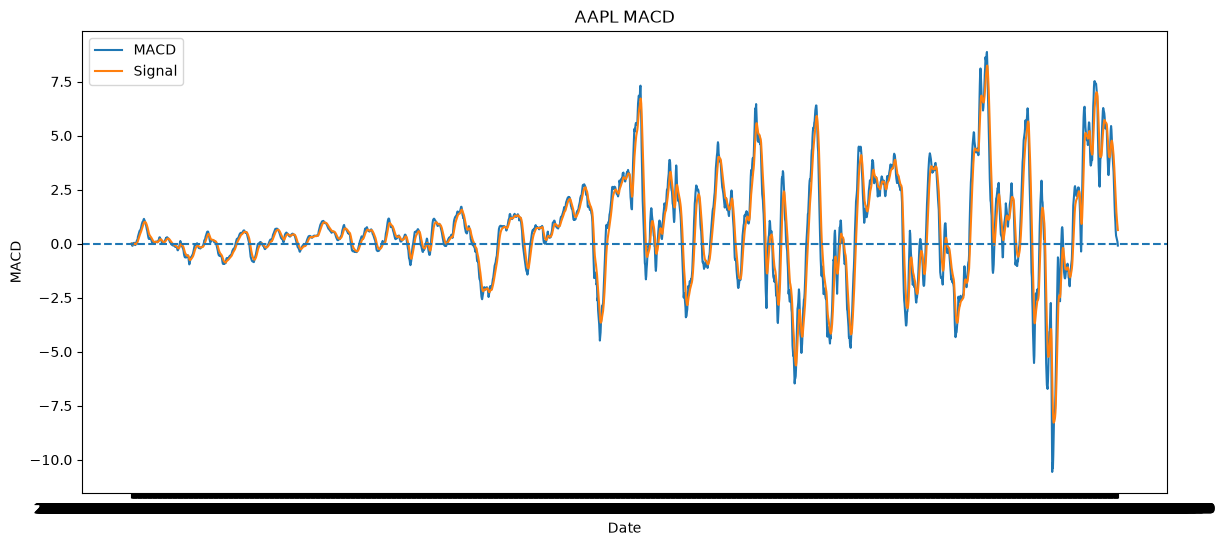

In [59]:
plt.figure(figsize=(14, 6))

plt.plot(
    data.index,
    data["MACD"],
    label="MACD"
)

plt.plot(
    data.index,
    data["MACD_signal"],
    label="Signal"
)

plt.axhline(0, linestyle="--")

plt.title("AAPL MACD")
plt.xlabel("Date")
plt.ylabel("MACD")
plt.legend()

plt.show()

In [ ]:
#18. Bollinger Bands
rolling_std_20 = (data["Adj Close"].rolling(20).std())


In [62]:
data["BB_middle"] = data["SMA_20"]

In [65]:
data["BB_upper"] = (data["SMA_20"] + 2 * rolling_std_20)

In [66]:
data["BB_lower"] = (data["SMA_20"] - 2 * rolling_std_20)

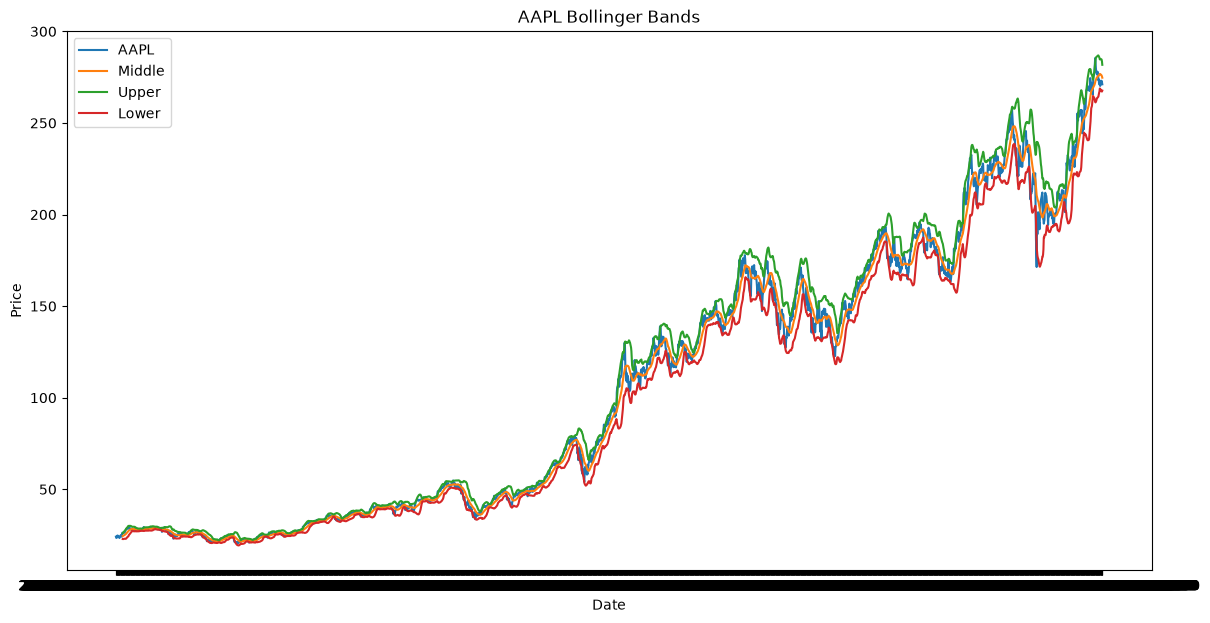

In [67]:
plt.figure(figsize=(14, 7))

plt.plot(
    data.index,
    data["Adj Close"],
    label="AAPL"
)

plt.plot(
    data.index,
    data["BB_middle"],
    label="Middle"
)

plt.plot(
    data.index,
    data["BB_upper"],
    label="Upper"
)

plt.plot(
    data.index,
    data["BB_lower"],
    label="Lower"
)

plt.title("AAPL Bollinger Bands")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()

plt.show()

In [69]:
data["BB_percent_b"] = ((data["Adj Close"] - data["BB_lower"])/ (data["BB_upper"] - data["BB_lower"]))

In [70]:
data["volume_change"] = (data["Volume"].pct_change())

In [71]:
data["volume_SMA20"] = (data["Volume"].rolling(20).mean())

In [72]:
data["relative_volume"] = (data["Volume"] / data["volume_SMA20"])

In [73]:
feature_columns = [
    "daily_return",
    "SMA_20",
    "SMA_50",
    "SMA_200",
    "EMA_12",
    "EMA_26",
    "price_to_SMA20",
    "SMA20_to_SMA50",
    "momentum_10d",
    "RSI_14",
    "MACD",
    "MACD_signal",
    "MACD_hist",
    "BB_middle",
    "BB_upper",
    "BB_lower",
    "BB_percent_b",
    "volume_change",
    "volume_SMA20",
    "relative_volume"
]

data[feature_columns].tail()

,daily_return,SMA_20,SMA_50,SMA_200,EMA_12,EMA_26,price_to_SMA20,SMA20_to_SMA50,momentum_10d,RSI_14,MACD,MACD_signal,MACD_hist,BB_middle,BB_upper,BB_lower,BB_percent_b,volume_change,volume_SMA20,relative_volume
Date,,,,,,,,,,,,,,,,,,,,
2025-12-24 00:00:00-05:00,0.005324,276.399649,270.219038,229.576619,273.495219,273.193288,-0.012058,0.022873,-0.017828,50.012074,0.301930,1.441249,-1.139319,276.399649,284.869111,267.930187,0.303238,-0.395770,44171280.0,0.405481
2025-12-26 00:00:00-05:00,-0.001497,276.192712,270.703749,229.861640,273.366391,273.153625,-0.012799,0.020277,-0.016653,49.168925,0.212766,1.195553,-0.982787,276.192712,284.822076,267.563348,0.295183,0.201624,43575800.0,0.493893
2025-12-29 00:00:00-05:00,0.001317,275.938904,271.233301,230.184734,273.312619,273.143496,-0.010589,0.017349,-0.016243,49.966601,0.169124,0.990267,-0.821143,275.938904,284.631301,267.246506,0.331921,0.101915,43754780.0,0.542002
2025-12-30 00:00:00-05:00,-0.002484,275.439264,271.652845,230.485502,273.162783,273.083880,-0.011257,0.013938,-0.003758,48.420900,0.078903,0.807994,-0.729091,275.439264,283.723722,267.154806,0.312868,-0.066438,42532375.0,0.520535
2025-12-31 00:00:00-05:00,-0.004468,274.724709,271.849788,230.777654,272.848818,272.938556,-0.013114,0.010575,-0.010014,45.690194,-0.089738,0.628448,-0.718186,274.724709,281.757748,267.691669,0.243873,0.232796,41213580.0,0.662248


In [74]:
data[feature_columns].isna().sum()

daily_return         1
SMA_20              19
SMA_50              49
SMA_200            199
EMA_12               0
EMA_26               0
price_to_SMA20      19
SMA20_to_SMA50      49
momentum_10d        10
RSI_14               1
MACD                 0
MACD_signal          0
MACD_hist            0
BB_middle           19
BB_upper            19
BB_lower            19
BB_percent_b        19
volume_change        1
volume_SMA20        19
relative_volume     19
dtype: int64

In [75]:
features = data[
    feature_columns
].dropna().copy()

In [76]:
features.shape

(2567, 20)

In [77]:
features.head()

,daily_return,SMA_20,SMA_50,SMA_200,EMA_12,EMA_26,price_to_SMA20,SMA20_to_SMA50,momentum_10d,RSI_14,MACD,MACD_signal,MACD_hist,BB_middle,BB_upper,BB_lower,BB_percent_b,volume_change,volume_SMA20,relative_volume
Date,,,,,,,,,,,,,,,,,,,,
2015-10-16 00:00:00-04:00,-0.007330,25.025021,25.154457,27.011853,24.921899,25.058386,-0.006526,-0.005146,0.005980,47.284859,-0.136487,-0.159463,0.022976,25.025021,25.867185,24.182858,0.403032,0.041385,200650080.0,0.782110
2015-10-19 00:00:00-04:00,0.006214,24.986064,25.137486,27.016075,24.936404,25.055260,0.001205,-0.006024,0.008576,49.316799,-0.118856,-0.151341,0.032486,24.986064,25.746288,24.225839,0.519810,-0.241468,196557520.0,0.605608
2015-10-20 00:00:00-04:00,0.018258,24.990206,25.110842,27.025986,25.018947,25.086199,0.019317,-0.004804,0.022101,54.857082,-0.067252,-0.134524,0.067272,24.990206,25.760535,24.219876,0.813324,0.645468,196281840.0,0.997908
2015-10-21 00:00:00-04:00,-0.000088,24.983937,25.112051,27.035874,25.088446,25.114680,0.019483,-0.005102,0.026900,54.825440,-0.026233,-0.112866,0.086632,24.983937,25.735313,24.232560,0.823909,-0.146476,197489540.0,0.846530
2015-10-22 00:00:00-04:00,0.015295,24.989534,25.113215,27.046064,25.207189,25.169909,0.034844,-0.004925,0.054795,59.231391,0.037280,-0.082836,0.120117,24.989534,25.766133,24.212936,1.060613,-0.003376,195776460.0,0.851054


In [78]:
features.isna().sum()

daily_return       0
SMA_20             0
SMA_50             0
SMA_200            0
EMA_12             0
EMA_26             0
price_to_SMA20     0
SMA20_to_SMA50     0
momentum_10d       0
RSI_14             0
MACD               0
MACD_signal        0
MACD_hist          0
BB_middle          0
BB_upper           0
BB_lower           0
BB_percent_b       0
volume_change      0
volume_SMA20       0
relative_volume    0
dtype: int64

In [79]:
data["future_return_1d"] = (
    data["Adj Close"].shift(-1)
    / data["Adj Close"]
    - 1
)

In [80]:
data["target_up"] = (
    data["future_return_1d"] > 0
).astype(int)

In [81]:
feature_corr = data[
    feature_columns
].corr()

In [82]:
feature_corr

,daily_return,SMA_20,SMA_50,SMA_200,EMA_12,EMA_26,price_to_SMA20,SMA20_to_SMA50,momentum_10d,RSI_14,MACD,MACD_signal,MACD_hist,BB_middle,BB_upper,BB_lower,BB_percent_b,volume_change,volume_SMA20,relative_volume
daily_return,1.000000,-0.010647,-0.010647,-0.013298,-0.010326,-0.011703,0.374981,0.010495,0.319616,0.305124,0.041475,-0.002277,0.141283,-0.010647,-0.010124,-0.011209,0.405569,-0.058068,-0.006014,-0.037973
SMA_20,-0.010647,1.000000,0.997747,0.984207,0.999547,0.999833,-0.021480,0.056115,-0.023157,-0.034200,0.196415,0.227361,-0.054994,1.000000,0.999088,0.998860,-0.041980,-0.003915,-0.725927,-0.001310
SMA_50,-0.010647,0.997747,1.000000,0.989293,0.996572,0.998565,-0.030326,0.000110,-0.027051,-0.064474,0.144265,0.167474,-0.041866,0.997747,0.997346,0.996012,-0.052873,-0.006092,-0.723200,-0.005326
SMA_200,-0.013298,0.984207,0.989293,1.000000,0.983086,0.985968,-0.052369,-0.062611,-0.043697,-0.114788,0.103959,0.114470,-0.011148,0.984207,0.984827,0.981216,-0.086179,-0.008818,-0.733906,-0.008630
EMA_12,-0.010326,0.999547,0.996572,0.983086,1.000000,0.999526,0.000925,0.065193,-0.003478,0.005456,0.221595,0.246686,-0.032232,0.999547,0.998626,0.998418,-0.022689,-0.004402,-0.727081,-0.004461
EMA_26,-0.011703,0.999833,0.998565,0.985968,0.999526,1.000000,-0.018493,0.043994,-0.019852,-0.014934,0.191472,0.218266,-0.043399,0.999833,0.999072,0.998522,-0.039260,-0.004707,-0.725698,-0.003023
price_to_SMA20,0.374981,-0.021480,-0.030326,-0.052369,0.000925,-0.018493,1.000000,0.338184,0.916677,0.879909,0.612865,0.425221,0.692368,-0.021480,-0.021611,-0.021287,0.903846,-0.022731,-0.100924,-0.131094
SMA20_to_SMA50,0.010495,0.056115,0.000110,-0.062611,0.065193,0.043994,0.338184,1.000000,0.218410,0.551867,0.678126,0.771148,-0.147922,0.056115,0.050552,0.062211,0.273229,0.020471,-0.248126,0.056030
momentum_10d,0.319616,-0.023157,-0.027051,-0.043697,-0.003478,-0.019852,0.916677,0.218410,1.000000,0.771874,0.516914,0.313490,0.721271,-0.023157,-0.022228,-0.024144,0.834573,-0.021007,-0.066758,-0.125045
RSI_14,0.305124,-0.034200,-0.064474,-0.114788,0.005456,-0.014934,0.879909,0.551867,0.771874,1.000000,0.646931,0.527800,0.490890,-0.034200,-0.035808,-0.032329,0.887692,-0.015650,-0.171573,-0.086618


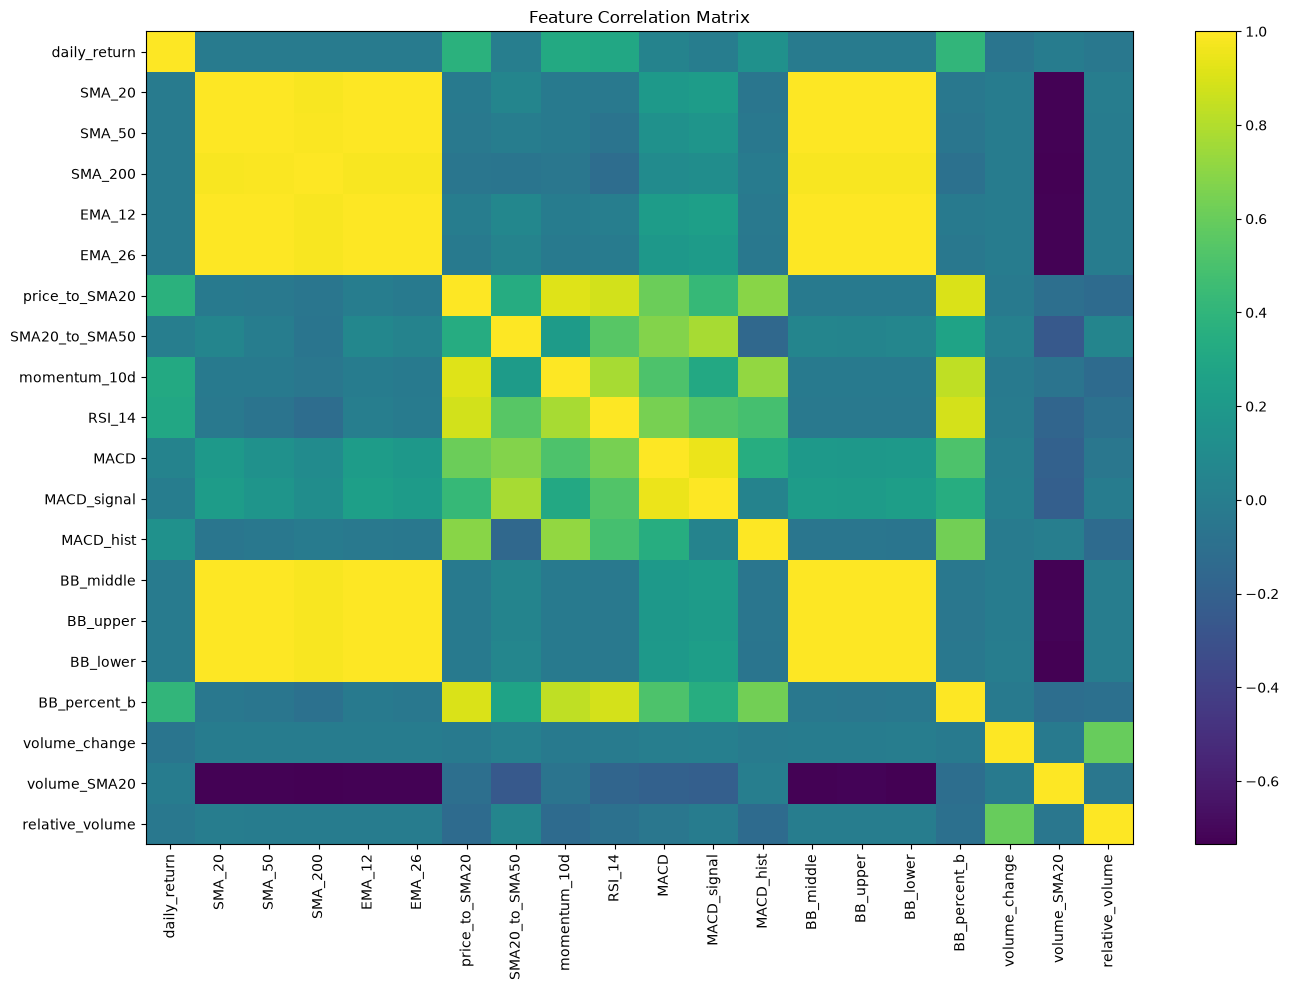

In [83]:
plt.figure(figsize=(14, 10))

plt.imshow(feature_corr, aspect="auto")

plt.xticks(
    range(len(feature_corr.columns)),
    feature_corr.columns,
    rotation=90
)

plt.yticks(
    range(len(feature_corr.columns)),
    feature_corr.columns
)

plt.title("Feature Correlation Matrix")

plt.colorbar()

plt.tight_layout()

plt.show()

In [85]:
data[
    [
        "Adj Close",
        "daily_return",
        "SMA_20",
        "SMA_50",
        "SMA_200",
        "RSI_14",
        "MACD",
        "BB_percent_b",
        "relative_volume"
    ]
].tail(5)

,Adj Close,daily_return,SMA_20,SMA_50,SMA_200,RSI_14,MACD,BB_percent_b,relative_volume
Date,,,,,,,,,
2025-12-24 00:00:00-05:00,273.066711,0.005324,276.399649,270.219038,229.576619,50.012074,0.301930,0.303238,0.405481
2025-12-26 00:00:00-05:00,272.657837,-0.001497,276.192712,270.703749,229.861640,49.168925,0.212766,0.295183,0.493893
2025-12-29 00:00:00-05:00,273.016876,0.001317,275.938904,271.233301,230.184734,49.966601,0.169124,0.331921,0.542002
2025-12-30 00:00:00-05:00,272.338684,-0.002484,275.439264,271.652845,230.485502,48.420900,0.078903,0.312868,0.520535
2025-12-31 00:00:00-05:00,271.122009,-0.004468,274.724709,271.849788,230.777654,45.690194,-0.089738,0.243873,0.662248
